# 06 - Preprocessing & Feature Engineering (BijliCast)

**CT-378 lifecycle, step 2 - part 1 (deterministic, past-only transforms)**

This notebook turns the integrated hourly table into the modelling table.
Lags and rolling statistics are row-local and causal, so they are built on the
full timeline *before* the split; that keeps real 24h/168h history at the
split boundaries. Imputation/scaling/encoding are statistical fits and stay
inside the scikit-learn `Pipeline` (notebook 07), fitted on train only.

**Row convention:** each row is the origin hour `t`. Every feature is known at
the end of `t`; the label is the household usage in `t+1`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
while not (ROOT / "datasets").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("Repo root:", ROOT)
from src.utils.config import (
    CATEGORICAL_FEATURES, FEATURE_COLUMNS, FEATURES_DATASET, FIGURES_DIR,
    HOUSE_COL, LAG_FEATURES, MERGED_DATASET, NUMERIC_FEATURES,
    REQUIRED_HISTORY, ROLLING_FEATURES, STATIC_NUMERIC_FEATURES,
    TABLES_DIR, TARGET, TIME_COL, WEATHER_FEATURES, ensure_dirs,
)
from src.features.build_features import (
    build_features, feature_summary, validate_features,
)
ensure_dirs()

Repo root: D:\BijliCast


## 1. Load the integrated dataset (`04_data_integration` output)

In [2]:
merged = pd.read_parquet(MERGED_DATASET)
merged[TIME_COL] = pd.to_datetime(merged[TIME_COL])
print("rows:", f"{len(merged):,}", "| houses:", merged[HOUSE_COL].nunique(),
      "| cities:", merged["city"].nunique())
print("range:", merged[TIME_COL].min(), "->", merged[TIME_COL].max())
merged[[TIME_COL, HOUSE_COL, "usage_kw", "temperature"]].head(3)

rows: 515,786 | houses: 59 | cities: 6
range: 2023-07-16 00:00:00 -> 2024-11-28 23:00:00


,datetime,house_id,usage_kw,temperature
0,2023-11-01 00:00:00,House#41,0.525333,17.9
1,2023-11-01 01:00:00,House#41,0.560500,18.2
2,2023-11-01 02:00:00,House#41,0.593833,18.6


## 2. Usage-gap profile per household

Meter outages are clustered, so the feature builder drops rows whose lag
history would be incomplete instead of interpolating usage values.

In [3]:
gap_rows = []
for house, g in merged.groupby(HOUSE_COL):
    s = g.set_index(TIME_COL)["usage_kw"].sort_index()
    s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="h"))
    missing = s.isna().to_numpy()
    run = longest = 0
    for flag in missing:
        run = run + 1 if flag else 0
        longest = max(longest, run)
    gap_rows.append({
        "house": house,
        "missing_pct": 100 * s.isna().mean(),
        "max_gap_hours": longest,
        "hours": len(s),
    })
gaps = pd.DataFrame(gap_rows)
print(gaps[["missing_pct", "max_gap_hours", "hours"]].describe().round(2).to_string())
print()
print("houses with >5% missing:", int((gaps.missing_pct > 5).sum()),
      "| with a gap >7 days:", int((gaps.max_gap_hours > 168).sum()))

       missing_pct  max_gap_hours     hours
count        59.00          59.00     59.00
mean          2.48         146.22   8742.14
std           4.93         309.71    884.24
min           0.00           0.00   5089.00
25%           0.00           0.00   8760.00
50%           0.31          23.00   8760.00
75%           1.93         117.00   8760.00
max          19.76        1584.00  11976.00

houses with >5% missing: 8 | with a gap >7 days: 13


### Plot 16 - Usage gap profile

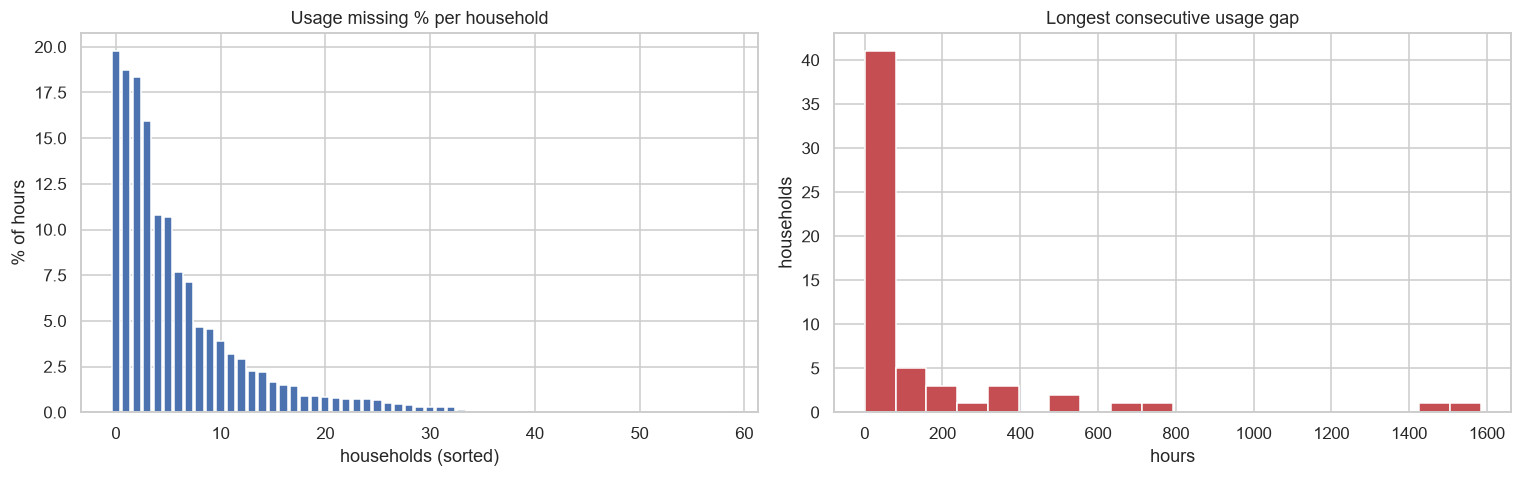

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ordered = gaps.sort_values("missing_pct", ascending=False)
axes[0].bar(range(len(ordered)), ordered.missing_pct, color="#4C72B0")
axes[0].set_title("Usage missing % per household")
axes[0].set_xlabel("households (sorted)")
axes[0].set_ylabel("% of hours")
axes[1].hist(gaps.max_gap_hours, bins=20, color="#C44E52")
axes[1].set_title("Longest consecutive usage gap")
axes[1].set_xlabel("hours")
axes[1].set_ylabel("households")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_usage_gaps.png", dpi=220, bbox_inches="tight")
plt.show()

## 3. Build the modelling table

Lags are expressed in hours **before the target hour**:

| Column | Definition |
|---|---|
| `lag_1h` | usage(t) - most recent reading |
| `lag_2h`, `lag_3h` | usage(t-1), usage(t-2) |
| `lag_24h` | usage(t-23) - same hour yesterday |
| `lag_168h` | usage(t-167) - same hour last week |
| `rolling_mean_3h` | mean of usage(t-2..t) |
| `rolling_mean_24h`, `rolling_std_24h` | over usage(t-23..t) |
| `next_hour_energy_kwh` | usage(t+1) - the label |

In [5]:
features = build_features(merged)
checks = validate_features(features, merged)

print("merged rows :", f"{len(merged):,}")
print("feature rows:", f"{len(features):,}")
print("dropped     :", f"{len(merged) - len(features):,}",
      f"({(1 - len(features) / len(merged)) * 100:.2f}%)")
print("houses      :", checks["houses"], "| model features:", checks["features"])
print("lag check   :", checks["verified_house"], "reproduced exactly")
print()
checks

merged rows : 515,786
feature rows: 480,209
dropped     : 35,577 (6.90%)
houses      : 59 | model features: 42
lag check   : House#10 reproduced exactly



{'rows': 480209,
 'houses': 59,
 'features': 42,
 'weather_missing_cells': 0,
 'verified_house': 'House#10',
 'rows_dropped_pct': 6.9,
 'mean_target': 0.7315,
 'max_target': 12.6618}

**Why rows are dropped:** a label is needed (`usage(t+1)`), plus a complete
168-hour history for `lag_168h` / rolling-24h. Rows inside or right after a
meter outage cannot be computed without inventing usage values, so they are
removed. Nothing is interpolated.

### Plot 17 - Rows kept per household

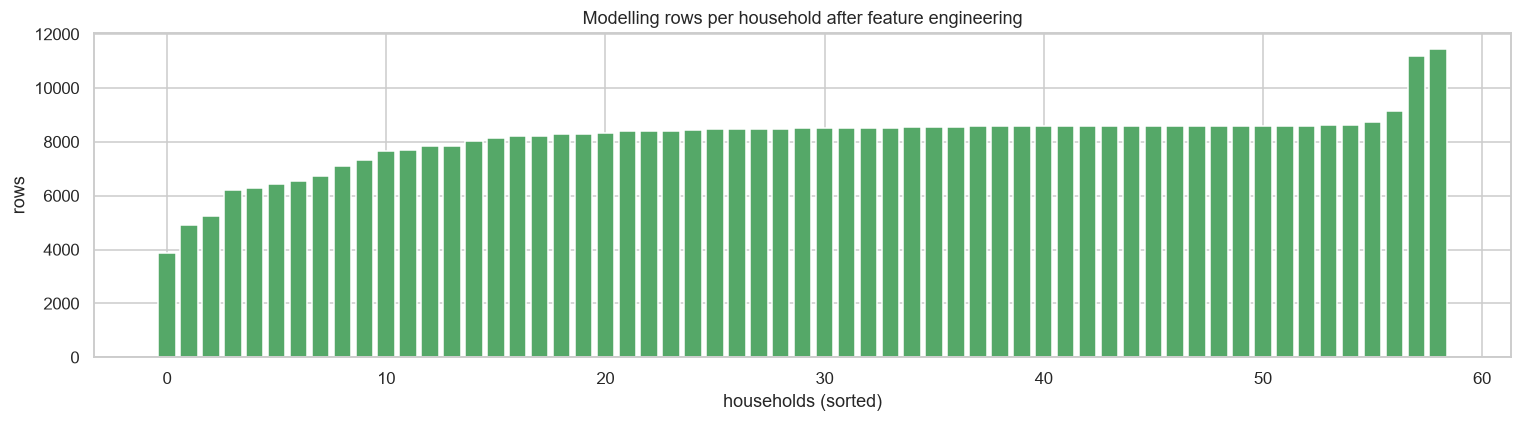

count       59.0
mean      8139.1
std       1182.6
min       3882.0
25%       8073.0
50%       8498.0
75%       8592.0
max      11462.0


In [6]:
per_house = features.groupby(HOUSE_COL).size().sort_values()
plt.figure(figsize=(14, 4))
plt.bar(range(len(per_house)), per_house.to_numpy(), color="#55A868")
plt.title("Modelling rows per household after feature engineering")
plt.xlabel("households (sorted)")
plt.ylabel("rows")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_rows_per_house.png", dpi=220, bbox_inches="tight")
plt.show()
print(per_house.describe().round(1).to_string())

## 4. Feature inventory

In [7]:
summary = feature_summary(features)
groups = {
    "weather (current hour)": WEATHER_FEATURES,
    "lags": LAG_FEATURES,
    "rolling": ROLLING_FEATURES,
    "calendar": ["hour", "day_of_week", "month", "is_weekend"],
    "static numeric": STATIC_NUMERIC_FEATURES,
    "categorical": CATEGORICAL_FEATURES,
}
for name, cols in groups.items():
    print(f"{name:<22} {len(cols):>2} features")
print(f"{'TOTAL':<22} {len(FEATURE_COLUMNS):>2} features")
print()
summary[summary.role == "feature"][["column", "dtype", "missing_pct", "min", "median", "max"]].to_string(index=False)

weather (current hour) 10 features
lags                    5 features
rolling                 3 features
calendar                4 features
static numeric         18 features
categorical             2 features
TOTAL                  42 features



'                   column   dtype  missing_pct    min    median       max\n                     city     str       0.0000    NaN       NaN       NaN\n                   lag_1h float64       0.0000    0.0    0.4361   12.6618\n                   lag_2h float64       0.0000    0.0    0.4361   12.6618\n                   lag_3h float64       0.0000    0.0    0.4361   12.6618\n                  lag_24h float64       0.0000    0.0    0.4358   12.6618\n                 lag_168h float64       0.0000    0.0    0.4340   12.6618\n          rolling_mean_3h float64       0.0000    0.0    0.4673   11.9275\n         rolling_mean_24h float64       0.0000    0.0    0.5006    7.1718\n          rolling_std_24h float64       0.0000    0.0    0.2895    3.6656\n              temperature float64       0.0000  -10.4   23.3000   47.0000\n                 humidity   int64       0.0000    5.0   61.0000  100.0000\n                      dew float64       0.0000  -23.4   11.9000   28.7000\n            precipitatio

### Plot 18 - Target distribution

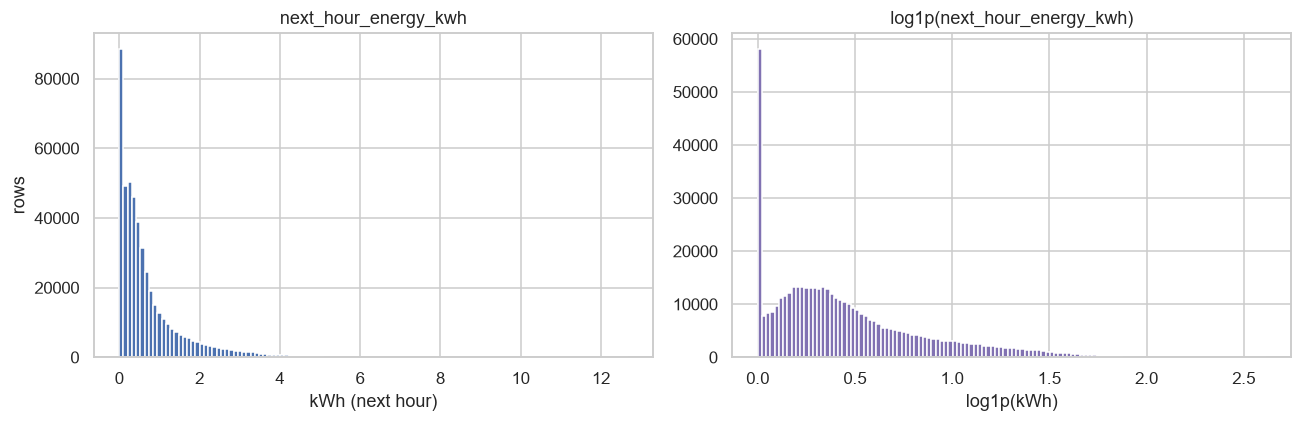

count    480209.000
mean          0.732
std           0.886
min           0.000
25%           0.175
50%           0.436
75%           0.927
max          12.662


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(features[TARGET], bins=120, color="#4C72B0")
axes[0].set_title("next_hour_energy_kwh")
axes[0].set_xlabel("kWh (next hour)")
axes[0].set_ylabel("rows")
axes[1].hist(np.log1p(features[TARGET]), bins=120, color="#8172B2")
axes[1].set_title("log1p(next_hour_energy_kwh)")
axes[1].set_xlabel("log1p(kWh)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_target_distribution.png", dpi=220, bbox_inches="tight")
plt.show()
print(features[TARGET].describe().round(3).to_string())

### Plot 19 - Usage autocorrelation (justifies 24h / 168h lags)

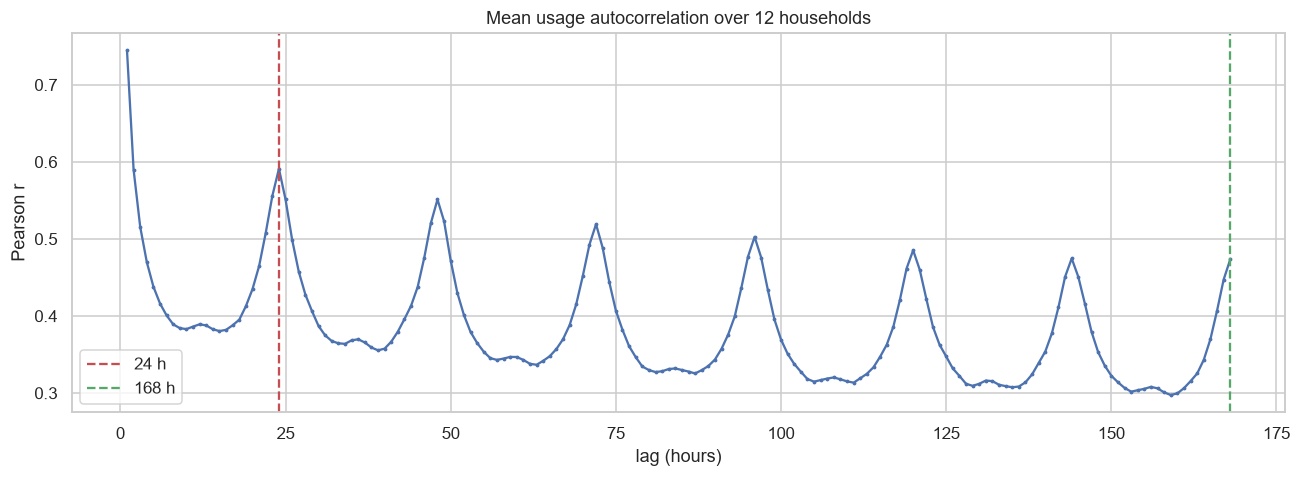

In [9]:
def autocorr_at(series, lag):
    a = series.to_numpy(dtype=float)[:-lag]
    b = series.to_numpy(dtype=float)[lag:]
    ok = ~(np.isnan(a) | np.isnan(b))
    if ok.sum() < 100:
        return np.nan
    return np.corrcoef(a[ok], b[ok])[0, 1]

houses = sorted(features[HOUSE_COL].unique())[:12]
curve = []
for house in houses:
    s = merged.loc[merged[HOUSE_COL] == house].set_index(TIME_COL)["usage_kw"].sort_index()
    s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="h"))
    curve.append([autocorr_at(s, k) for k in range(1, 169)])
acf = np.nanmean(np.array(curve, dtype=float), axis=0)

plt.figure(figsize=(12, 4.5))
plt.plot(range(1, 169), acf, marker=".", markersize=3, color="#4C72B0")
plt.axvline(24, color="#C44E52", ls="--", label="24 h")
plt.axvline(168, color="#55A868", ls="--", label="168 h")
plt.title("Mean usage autocorrelation over 12 households")
plt.xlabel("lag (hours)")
plt.ylabel("Pearson r")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_usage_acf.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 20 - Correlation of the target with numeric features

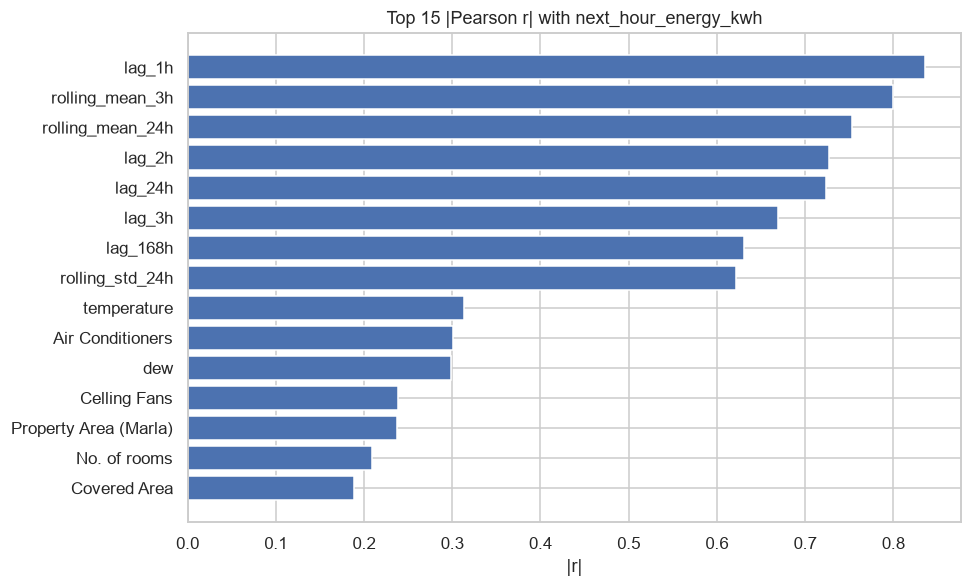

'lag_1h                   0.835\nrolling_mean_3h          0.799\nrolling_mean_24h         0.753\nlag_2h                   0.727\nlag_24h                  0.724\nlag_3h                   0.669\nlag_168h                 0.631\nrolling_std_24h          0.622\ntemperature              0.313\nAir Conditioners         0.301\ndew                      0.299\nCelling Fans             0.238\nProperty Area (Marla)    0.237\nNo. of rooms             0.209\nCovered Area             0.189'

In [10]:
corr = (
    features[NUMERIC_FEATURES]
    .corrwith(features[TARGET])
    .abs()
    .sort_values(ascending=False)
    .head(15)
)
plt.figure(figsize=(9, 5.5))
plt.barh(corr.index[::-1], corr.to_numpy()[::-1], color="#4C72B0")
plt.title("Top 15 |Pearson r| with next_hour_energy_kwh")
plt.xlabel("|r|")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_target_correlations.png", dpi=220, bbox_inches="tight")
plt.show()
corr.round(3).to_string()

### Plot 21 - Missing values in the feature matrix

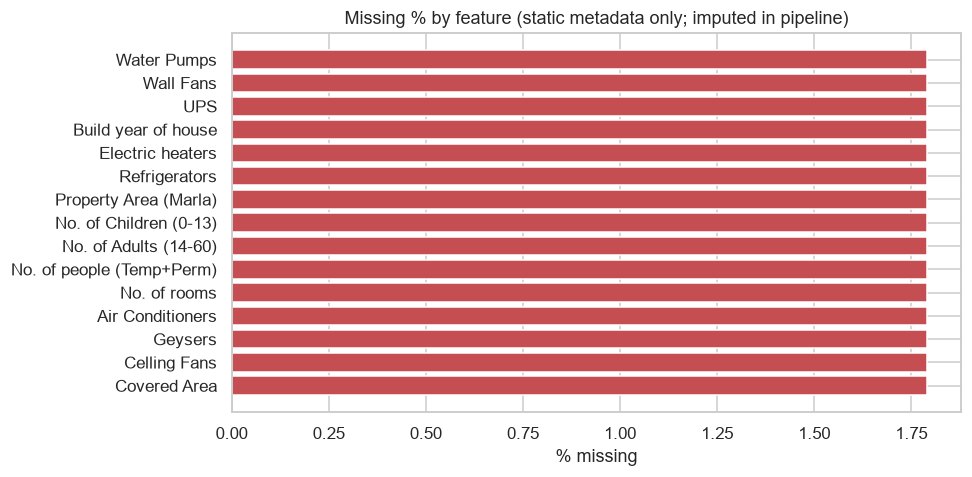

Water Pumps                  1.79
Wall Fans                    1.79
UPS                          1.79
Build year of house          1.79
Electric heaters             1.79
Refrigerators                1.79
Property Area (Marla)        1.79
No. of Children (0-13)       1.79
No. of Adults (14-60)        1.79
No. of people (Temp+Perm)    1.79
No. of rooms                 1.79
Air Conditioners             1.79
Geysers                      1.79
Celling Fans                 1.79
Covered Area                 1.79


In [11]:
missing = (
    features[FEATURE_COLUMNS].isna().mean().mul(100).sort_values(ascending=False)
)
missing = missing[missing > 0]
if missing.empty:
    print("no missing feature values")
else:
    plt.figure(figsize=(9, max(3, 0.3 * len(missing))))
    plt.barh(missing.index[::-1], missing.to_numpy()[::-1], color="#C44E52")
    plt.title("Missing % by feature (static metadata only; imputed in pipeline)")
    plt.xlabel("% missing")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "06_feature_missing.png", dpi=220, bbox_inches="tight")
    plt.show()
    print(missing.round(2).to_string())

## 5. Leakage checks

`validate_features` already asserted:
- single row per `(house_id, hour)`;
- no missing label, no missing lag/rolling/weather values;
- `target(t) == lag_1h(t+1h)` on every contiguous pair;
- every lag/rolling/rolling-std recomputed from raw usage for a gap-free house;
- raw `usage_kw` is not a model input.

In [12]:
assert "usage_kw" not in features.columns
assert features[TARGET].notna().all()
for col in REQUIRED_HISTORY:
    assert features[col].notna().all(), col
print("leakage checks passed")
print("feature matrix shape:", features[FEATURE_COLUMNS].shape)

leakage checks passed
feature matrix shape: (480209, 42)


## 6. Save the modelling table

In [13]:
features.to_parquet(FEATURES_DATASET, index=False)
summary.to_csv(TABLES_DIR / "feature_summary.csv", index=False)
print("saved ->", FEATURES_DATASET)
print("saved ->", TABLES_DIR / "feature_summary.csv")

saved -> D:\BijliCast\data\processed\features_dataset.parquet
saved -> D:\BijliCast\reports\tables\feature_summary.csv


## Findings - Notebook 06

- **480,209 rows x 45 columns**, 59 households, **42 model features** (requirement: >= 15).
- 6.9% of rows were dropped: 2.5% have no next-hour label, the rest lack a complete lag history around outages. No usage value was interpolated.
- `lag_1h` is by far the strongest predictor (autocorrelation decays with lag, with local peaks at 24h and 168h) - this validates the chosen lags.
- Only static metadata has missing values (~1.7%), which the pipeline imputes from training statistics.
- Every leakage assertion passed; `usage_kw` is absent from the feature matrix.